# 01 — Datos

Construcción del dataset de entrenamiento para Text-to-SQL (español → MySQL 8.4.10).

**Pipeline**

1. `scripts/spider_a_mysql.py` carga las 140 bases de entrenamiento de Spider en MySQL.
2. `scripts/filtrar_spider.py` convierte el SQL de SQLite a MySQL con `sqlglot` y conserva solo los pares cuyo resultado coincide en ambos motores.
3. `scripts/seleccionar_spider.py` elige 2,000 pares (cuotas por nivel, máximo 40 por base).
4. `scripts/traducir_spider.py` traduce las preguntas con `Helsinki-NLP/opus-mt-en-es` (100 revisadas a mano).
5. 12 esquemas propios: `cargar_esquemas.py`, `poblar_esquemas.py` (semilla 2026) y pares escritos en español, filtrados con `filtrar_propios.py`.
6. `scripts/dividir.py` ensambla `datos/entrenamiento.jsonl` y verifica que no haya fuga de esquemas de validación.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
leer = lambda p: [json.loads(l) for l in open(ROOT / p, encoding='utf-8') if l.strip()]
train = pd.DataFrame(leer('datos/entrenamiento.jsonl'))
evalu = pd.DataFrame(leer('datos/eval_loss.jsonl'))
print('pares de entrenamiento:', len(train), '| pares solo para la curva de loss:', len(evalu))
print('esquemas distintos en entrenamiento:', train.db_id.nunique())

pares de entrenamiento: 2403 | pares solo para la curva de loss: 142
esquemas distintos en entrenamiento: 144


## Composición del dataset

In [2]:
tabla = pd.crosstab(train.fuente, train.nivel)[['facil', 'media', 'dificil']]
tabla['total'] = tabla.sum(axis=1)
tabla.loc['total'] = tabla.sum()
tabla

nivel,facil,media,dificil,total
fuente,,,,
propio,108,201,236,545
spider,465,746,647,1858
total,573,947,883,2403


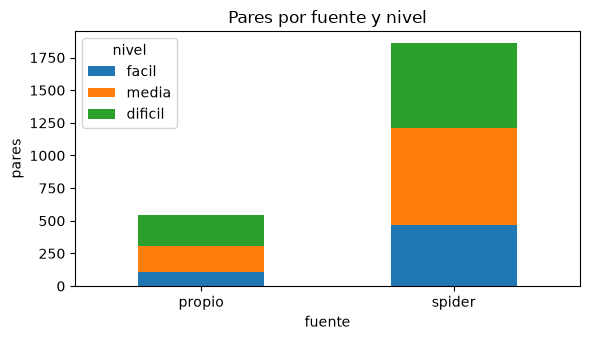

In [3]:
pd.crosstab(train.fuente, train.nivel)[['facil', 'media', 'dificil']].plot(kind='bar', stacked=True, figsize=(6, 3.5))
plt.title('Pares por fuente y nivel'); plt.ylabel('pares'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

Las preguntas difíciles pesan 3 veces en la evaluación oculta, por eso se priorizaron: Spider casi no tiene `WITH` ni funciones de ventana, y esa parte la cubren los 12 esquemas propios.

## Descartes

Solo se aceptan pares cuya consulta se ejecuta sin error en MySQL 8.4.10 con el usuario de solo lectura y el `sql_mode` por defecto (incluye `ONLY_FULL_GROUP_BY`).

In [4]:
desc = pd.read_csv(ROOT / 'datos/descartes.csv')
resumen = desc.groupby(['fuente', 'motivo']).size().unstack(0).fillna(0).astype(int)
resumen.loc['total'] = resumen.sum()
resumen

fuente,propio,spider
motivo,,
error_mysql,0,164
resultado_distinto,0,218
resultado_vacio,20,238
total,20,620


In [5]:
carga = pd.read_csv(ROOT / 'datos/esquemas/spider_carga.csv')
print('bases de Spider cargadas:', (carga.estado == 'ok').sum(), 'de', len(carga))
print('pares de Spider procesados: 7000 | aceptados tras el filtro: 6380 | descartados:', (desc.fuente == 'spider').sum())

bases de Spider cargadas: 140 de 140
pares de Spider procesados: 7000 | aceptados tras el filtro: 6380 | descartados: 620


Motivos de descarte en Spider:

- `resultado_vacio`: la consulta es válida pero no devuelve filas.
- `resultado_distinto`: SQLite y MySQL devuelven filas diferentes (por ejemplo, comparación de texto sensible a mayúsculas).
- `error_mysql`: falla en MySQL, sobre todo por `ONLY_FULL_GROUP_BY`.

## Largo de los ejemplos

Decide el `max_length` del entrenamiento.

count    2403.0
mean     1046.0
std       684.0
min       255.0
50%       822.0
90%      1882.0
95%      2034.0
99%      2596.0
max      4980.0
Name: tokens, dtype: float64
caben en 1024: 60.7%
caben en 1536: 70.7%
caben en 2048: 95.5%
caben en 3072: 99.3%


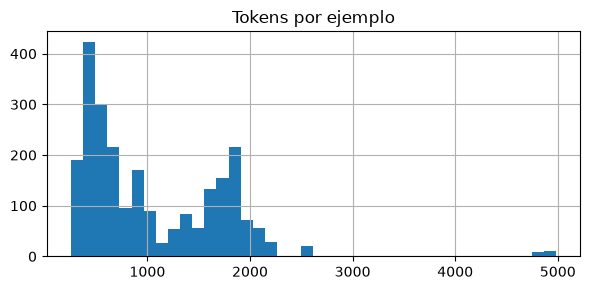

In [6]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-Coder-1.5B-Instruct')
    # ~70 tokens aproximan el system prompt y el formato de chat que se agrega alrededor
    train['tokens'] = [len(tok(e + p + s).input_ids) + 70 for e, p, s in zip(train.esquema, train.pregunta, train.sql)]
    print(train.tokens.describe(percentiles=[.5, .9, .95, .99]).round(0))
    for corte in (1024, 1536, 2048, 3072):
        print(f'caben en {corte}: {(train.tokens <= corte).mean():.1%}')
    train.tokens.clip(upper=5000).hist(bins=40, figsize=(6, 3)); plt.title('Tokens por ejemplo'); plt.tight_layout(); plt.show()
except Exception as e:
    print('No se pudo cargar el tokenizador:', e)

Con `max_length = 2048` entra cerca del 95 % de los pares; los más largos son de bases enormes de Spider (por ejemplo `baseball_1`), poco parecidas a los esquemas de 5 a 10 tablas de la evaluación oculta.

## Ejemplos

In [7]:
for _, r in train.sample(4, random_state=2026).iterrows():
    print(f'[{r.fuente} | {r.nivel} | {r.db_id}]')
    print('P:', r.pregunta)
    print('SQL:', r.sql, '\n')

[propio | dificil | tr_hospital]
P: Muestra el total recaudado por trimestre de 2025 en citas atendidas. Devuelve: trimestre, total
SQL: SELECT QUARTER(fecha_hora) AS trimestre, SUM(costo) AS total FROM citas WHERE estado = 'atendida' AND YEAR(fecha_hora) = 2025 GROUP BY QUARTER(fecha_hora) ORDER BY trimestre 

[spider | facil | inn_1]
P: ¿Cuál es la decoración de la habitación Recluso y desafío? Devuelve: decor
SQL: SELECT decor FROM Rooms WHERE roomName = 'Recluse and defiance' 

[propio | facil | tr_planilla]
P: Lista los puestos con salario mínimo mayor a 8000 quetzales. Devuelve: nom_pue, sal_min
SQL: SELECT nom_pue, sal_min FROM pue WHERE sal_min > 8000 

[spider | facil | products_gen_characteristics]
P: ¿Cuál es la descripción de la categoría de producto con el código 'Spices'? Devuelve: product_category_description
SQL: SELECT product_category_description FROM Ref_Product_Categories WHERE product_category_code = 'Spices' 



## Esquemas propios

12 bases de 8 o 9 tablas, con `COMMENT` en tablas y columnas y nombres en tres estilos:

- **Español:** supermercado, universidad, banco, hospital.
- **Inglés:** telecom, aerolinea, tienda_online, cine.
- **Abreviado:** inventario, planilla, delivery, seguros (por ejemplo `pol_id`, `fec_sini`, `mto_ase`).

Todos los datos son ficticios y se generan con semilla 2026.

In [8]:
propios = train[train.fuente == 'propio']
pd.crosstab(propios.db_id, propios.nivel)[['facil', 'media', 'dificil']]

nivel,facil,media,dificil
db_id,,,
tr_aerolinea,8,15,19
tr_banco,9,18,22
tr_cine,8,13,14
tr_delivery,8,15,16
tr_hospital,10,18,19
tr_inventario,8,16,18
tr_planilla,8,15,17
tr_seguros,8,14,16
tr_supermercado,15,26,31


## Pendiente de revisión humana

El filtro por ejecución garantiza que el SQL corre y devuelve filas, **no** que responda a la pregunta. Para medir esa diferencia, `datos/revision_manual.csv` contiene 50 pares propios y 30 traducciones de Spider elegidos al azar. El porcentaje de respuestas "no" es la tasa de error del dataset y se reporta en la presentación.